# HOG + kNN

**Mục tiêu:** mô tả đường nét/hình dạng bằng HOG, phân loại bằng kNN và so sánh với HSV.
Pipeline: BGR → resize 64×64 → ảnh xám → HOG → chuẩn hóa L2 → kNN.

## 1. Thư viện và split dùng chung
Nếu thiếu thư viện thì bỏ dấu `#` ở dòng cài đặt bên dưới.
Các bảng dùng màu cố định để đọc được trên giao diện sáng và tối.

In [1]:
# %pip install numpy pandas opencv-python matplotlib scikit-learn joblib threadpoolctl

from pathlib import Path
import sys
import json
import hashlib
import inspect
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display, HTML, Image
from threadpoolctl import threadpool_limits

PROJECT = Path.cwd()
if PROJECT.name == "code":
    PROJECT = PROJECT.parent
sys.path.insert(0, str(PROJECT / "code"))
from preprocessing import read_bgr, preprocess
from features_hog import create_hog, hog_features, predict_hog
from train_hog import run_training
from plot_validation import plot_results

DATA = PROJECT / "data/raw"
OUTPUT = PROJECT / "results/hog"
OUTPUT.mkdir(parents=True, exist_ok=True)
train = pd.read_csv(PROJECT / "splits/train.csv", keep_default_na=False)
validation = pd.read_csv(PROJECT / "splits/validation.csv", keep_default_na=False)
names = pd.read_csv(PROJECT / "configs/class_names.csv").set_index("class_id")
assert not (set(train.track_id) & set(validation.track_id))
print("Train:", len(train), "| Validation:", len(validation), "| Không đọc test")


def table_html(html):
    import re
    html = re.sub(r"<style.*?</style>", "", html, flags=re.DOTALL)
    header = "color:#172b4d !important;background:#e8eef5 !important;padding:8px 12px;border:1px solid #ccd5df;white-space:nowrap;"
    body = "color:#172b4d !important;background:#ffffff !important;padding:8px 12px;border:1px solid #ccd5df;white-space:nowrap;"
    html = re.sub(r"<th(?=[ >])", '<th style="' + header + '"', html)
    html = re.sub(r"<td(?=[ >])", '<td style="' + body + '"', html)
    html = html.replace("<table ", '<table style="border-collapse:collapse;font-family:Arial,sans-serif;font-size:13px;" ')
    return '<div style="background:#fff;color:#172b4d;padding:10px;max-width:100%;overflow-x:auto;">' + html + '</div>'


def show_table(table):
    # Series (một cột) được chuyển thành bảng trước khi hiển thị.
    if isinstance(table, pd.Series):
        table = table.to_frame(name="Giá trị")
    display(HTML(table_html(table.to_html(border=0))))

Train: 31380 | Validation: 7829 | Không đọc test


## 2. HOG hoạt động như thế nào?

1. Chuyển ảnh sang xám để mô tả đường nét.
2. Tính độ lớn và hướng gradient: pixel thay đổi sáng mạnh đóng góp nhiều hơn.
3. Chia ảnh thành các **cell**, cộng phiếu hướng vào 9 bin (hướng không dấu 0–180°).
4. Ghép **2×2 cell** thành một block và chuẩn hóa L2-Hys; stride bằng một cell.
5. Ghép các block thành vector; chuẩn hóa L2 toàn vector trước khi dùng kNN.

OpenCV làm phần HOG qua `HOGDescriptor`; không phải tự dùng Canny để thay thế HOG.
L2-Hys từng block và L2 toàn vector là hai bước khác nhau. Cả hai xử lý riêng từng ảnh,
không cần fit StandardScaler hoặc học thống kê validation.
Không bật gamma correction, signed gradient hoặc CLAHE trong thí nghiệm này.

Số chiều ảnh 64×64:
- Cell 8, block 16, stride 8: `7×7 block × 4 cell × 9 hướng = 1.764`.
- Cell 16, block 32, stride 16: `3×3 block × 4 cell × 9 hướng = 324`.

Cell nhỏ giữ nhiều chi tiết và tốn chiều hơn; cell lớn thô hơn. Validation quyết định cấu hình chọn.

In [2]:
print(inspect.getsource(create_hog))
print(inspect.getsource(hog_features))

def create_hog(cell_size=8, size=(64, 64)):
    """Block gồm 2x2 cell, stride một cell, 9 hướng không dấu."""
    if cell_size not in (8, 16) or tuple(size) != (64, 64):
        raise ValueError('Cấu hình hỗ trợ: ảnh 64x64, cell 8 hoặc 16 pixel')
    return cv2.HOGDescriptor(
        _winSize=tuple(size),
        _blockSize=(2 * cell_size, 2 * cell_size),
        _blockStride=(cell_size, cell_size),
        _cellSize=(cell_size, cell_size),
        _nbins=9,
        _histogramNormType=cv2.HOGDescriptor_L2Hys,
        _L2HysThreshold=0.2,
        _gammaCorrection=False,
        _signedGradient=False,
    )

def hog_features(image, cell_size=8, size=(64, 64)):
    """Ảnh BGR -> gray -> HOG (L2-Hys từng block) -> L2 toàn vector."""
    gray = preprocess(image, size=size, color='gray')
    vector = create_hog(cell_size, size).compute(gray).flatten()
    norm = np.linalg.norm(vector)
    return vector / norm if norm > 0 else vector



## 3. Minh họa gradient và vector HOG

Chọn một ảnh STOP trong **train**. Ảnh gradient dưới đây minh họa nơi có thay đổi sáng;
nó không phải hình tái tạo vector HOG và không thay cho phép tính HOG của OpenCV.

Số chiều: 1764 | Chuẩn L2: 1.0


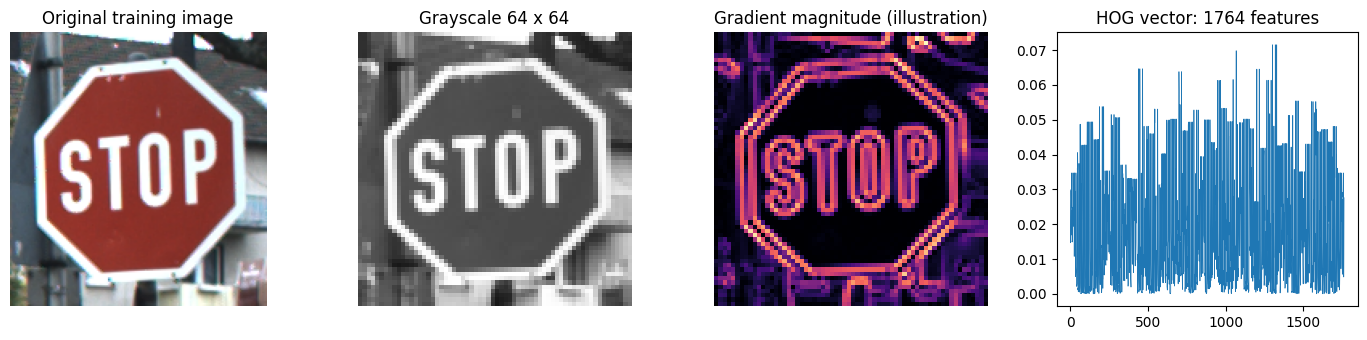

In [3]:
clear_file = PROJECT / "results/notebook/clear_training_samples.csv"
if clear_file.exists():
    sample_path = pd.read_csv(clear_file).query("class_id == 14").iloc[0].path
else:
    sample_path = train.query("class_id == 14").sort_values("path").iloc[-1].path

image = read_bgr(DATA / sample_path)
gray = preprocess(image, color="gray")
gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=1)
gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=1)
magnitude = cv2.magnitude(gx, gy)
vector = hog_features(image, cell_size=8)
print("Số chiều:", len(vector), "| Chuẩn L2:", float(np.linalg.norm(vector)))

fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
axes[0].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
axes[0].set_title("Original training image")
axes[1].imshow(gray, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Grayscale 64 x 64")
axes[2].imshow(magnitude, cmap="magma")
axes[2].set_title("Gradient magnitude (illustration)")
axes[3].plot(vector, linewidth=0.5)
axes[3].set_title("HOG vector: 1764 features")
for ax in axes[:3]:
    ax.axis("off")
plt.tight_layout()
plt.savefig(OUTPUT / "hog_example.png", dpi=150)
plt.show()

## 4. Huấn luyện và chọn tham số trên validation

Grid: cell=8/16, k=3/5/7, khoảng cách Euclidean/Manhattan: **12 cấu hình**, bằng ngân sách HSV.
Bỏ phiếu đồng đều, brute force, số hướng 9 và block 2×2 cell cố định.
Chọn Macro-F1 cao nhất; hòa thì Accuracy, ít chiều hơn, k nhỏ hơn, thứ tự khoảng cách trong grid.

Đổi `RUN_TRAINING = True` để chạy lại. HOG nhiều chiều nên tìm láng giềng có thể mất vài phút.
Mô hình được fit **chỉ trên train**; không gộp validation vào train ở bước này.
Chạy lại sẽ thay mô hình/kết quả HOG, không thay split hoặc kết quả HSV.

In [4]:
RUN_TRAINING = False
if RUN_TRAINING or not (OUTPUT / "summary.json").exists():
    summary = run_training(PROJECT)
else:
    summary = json.loads((OUTPUT / "summary.json").read_text(encoding="utf-8"))
    print("Dùng kết quả HOG đã chạy.")

for name, expected_hash in summary["split_sha256"].items():
    actual = hashlib.sha256((PROJECT / f"splits/{name}.csv").read_bytes()).hexdigest()
    assert actual == expected_hash, "Split khác kết quả đã lưu; cần huấn luyện lại"
assert not summary["test_evaluated"]

Dùng kết quả HOG đã chạy.


## 5. Kết quả validation thực tế

Toàn bộ 12 cấu hình đều được công bố. Thời gian dự đoán là một batch toàn validation chia số ảnh;
toàn luồng còn gồm đọc đĩa, resize, ảnh xám, HOG và chuẩn hóa. Đây chưa phải latency một ảnh đo lặp.

,cell_size,block_stride,orientations,k,distance,n_features,accuracy,macro_f1,classifier_ms_per_image,end_to_end_ms_per_image
5,8,8,9,7,manhattan,1764,0.8219,0.7761,18.1186,19.0872
3,8,8,9,5,manhattan,1764,0.8182,0.7759,19.3473,20.3159
2,8,8,9,5,euclidean,1764,0.7988,0.7646,3.0534,4.0220
1,8,8,9,3,manhattan,1764,0.8048,0.7637,23.5410,24.5096
11,16,16,9,7,manhattan,324,0.8016,0.7622,3.5426,4.2916
0,8,8,9,3,euclidean,1764,0.7936,0.7618,2.7228,3.6914
4,8,8,9,7,euclidean,1764,0.7984,0.7607,1.7081,2.6767
9,16,16,9,5,manhattan,324,0.7991,0.7594,3.4090,4.1580
7,16,16,9,3,manhattan,324,0.7932,0.7585,3.5365,4.2854
10,16,16,9,7,euclidean,324,0.7792,0.7457,0.3773,1.1263


Cấu hình được chọn:


,Giá trị
cell_size,8
block_cells,2
block_stride,8
orientations,9
k,7
distance,manhattan
weights,uniform
n_features,1764
accuracy,0.821944
macro_f1,0.776102


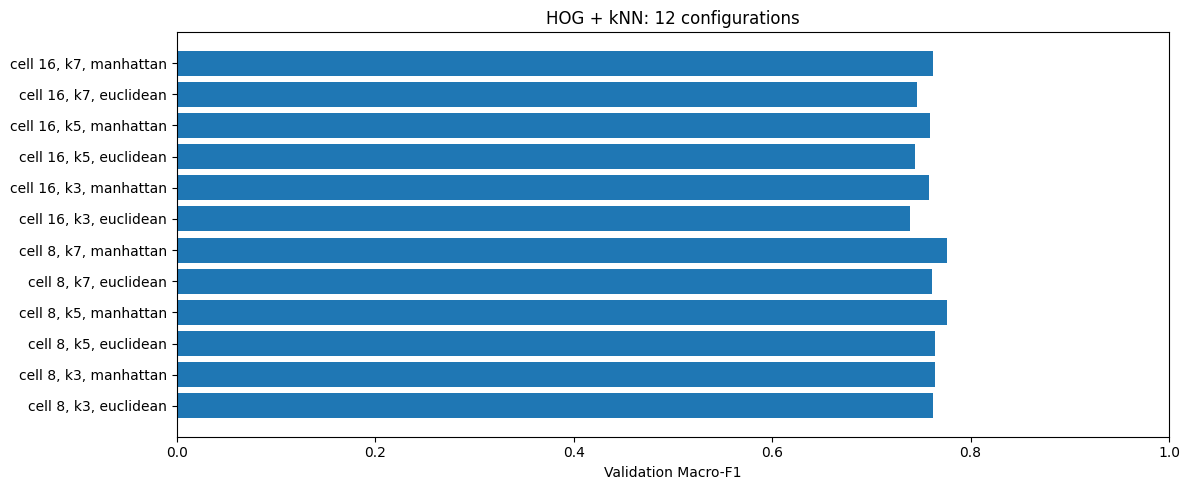

In [5]:
results = pd.read_csv(OUTPUT / "validation_results.csv")
ranked = results.sort_values(["macro_f1", "accuracy", "n_features", "k"],
                             ascending=[False, False, True, True])
columns = ["cell_size", "block_stride", "orientations", "k", "distance", "n_features",
           "accuracy", "macro_f1", "classifier_ms_per_image", "end_to_end_ms_per_image"]
show_table(ranked[columns].round(4))
print("Cấu hình được chọn:")
show_table(pd.Series(summary["best"]))

labels = [f"cell {r.cell_size}, k{r.k}, {r.distance}" for r in results.itertuples()]
plt.figure(figsize=(12, 5))
plt.barh(labels, results.macro_f1)
plt.xlim(0, 1)
plt.xlabel("Validation Macro-F1")
plt.title("HOG + kNN: 12 configurations")
plt.tight_layout()
plt.savefig(OUTPUT / "validation_search.png", dpi=150)
plt.show()

## 6. So sánh HSV–HOG và ma trận nhầm lẫn

Cả hai phương pháp dùng cùng train/validation, kNN, weights, khoảng cách và ngân sách 12 cấu hình.
Cách biểu diễn và chuẩn hóa phù hợp từng loại: HSV L1, HOG block L2-Hys rồi L2 toàn cục.
Đây là so sánh **validation sau chọn tham số**, chưa là kết luận trên test hoặc về phương pháp kết hợp.

Biểu đồ thời gian chỉ mang tính tham khảo từ một lượt trên cùng máy/4 thread;
cache, tải máy và số chiều khác nhau. Cần đo lại cùng điều kiện khi đánh giá cuối.
Ma trận ảnh bên dưới chuẩn hóa theo **hàng** để quan sát các lớp ít ảnh;
CSV lưu số đếm gốc. Trục là ID lớp 0–42, ánh xạ tên có trong `configs/class_names.csv`.

,method,split,search_budget,accuracy,macro_f1,n_features,k,distance,classifier_ms_per_image,end_to_end_ms_per_image
0,HSV + kNN,validation,12,0.1745,0.1341,256,3,manhattan,2.4781,2.8828
1,HOG + kNN,validation,12,0.8219,0.7761,1764,7,manhattan,18.1186,19.0872


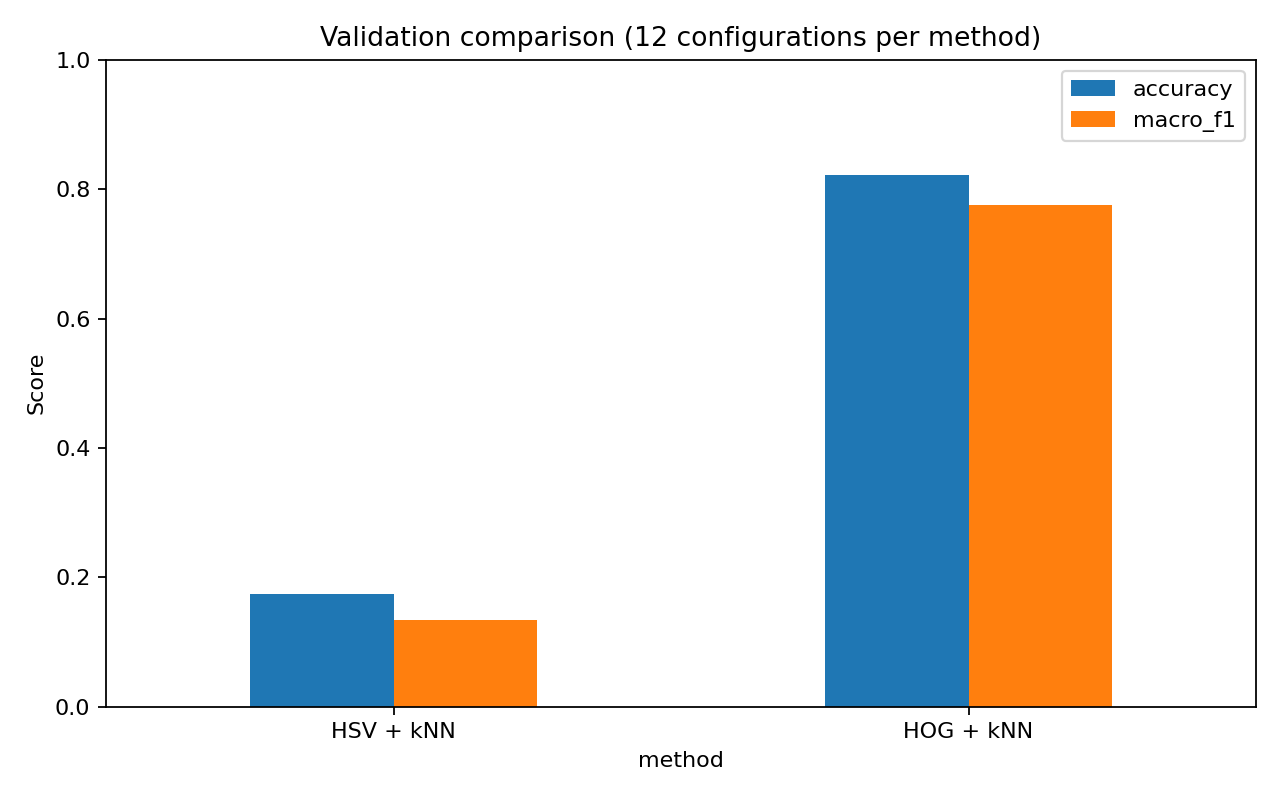

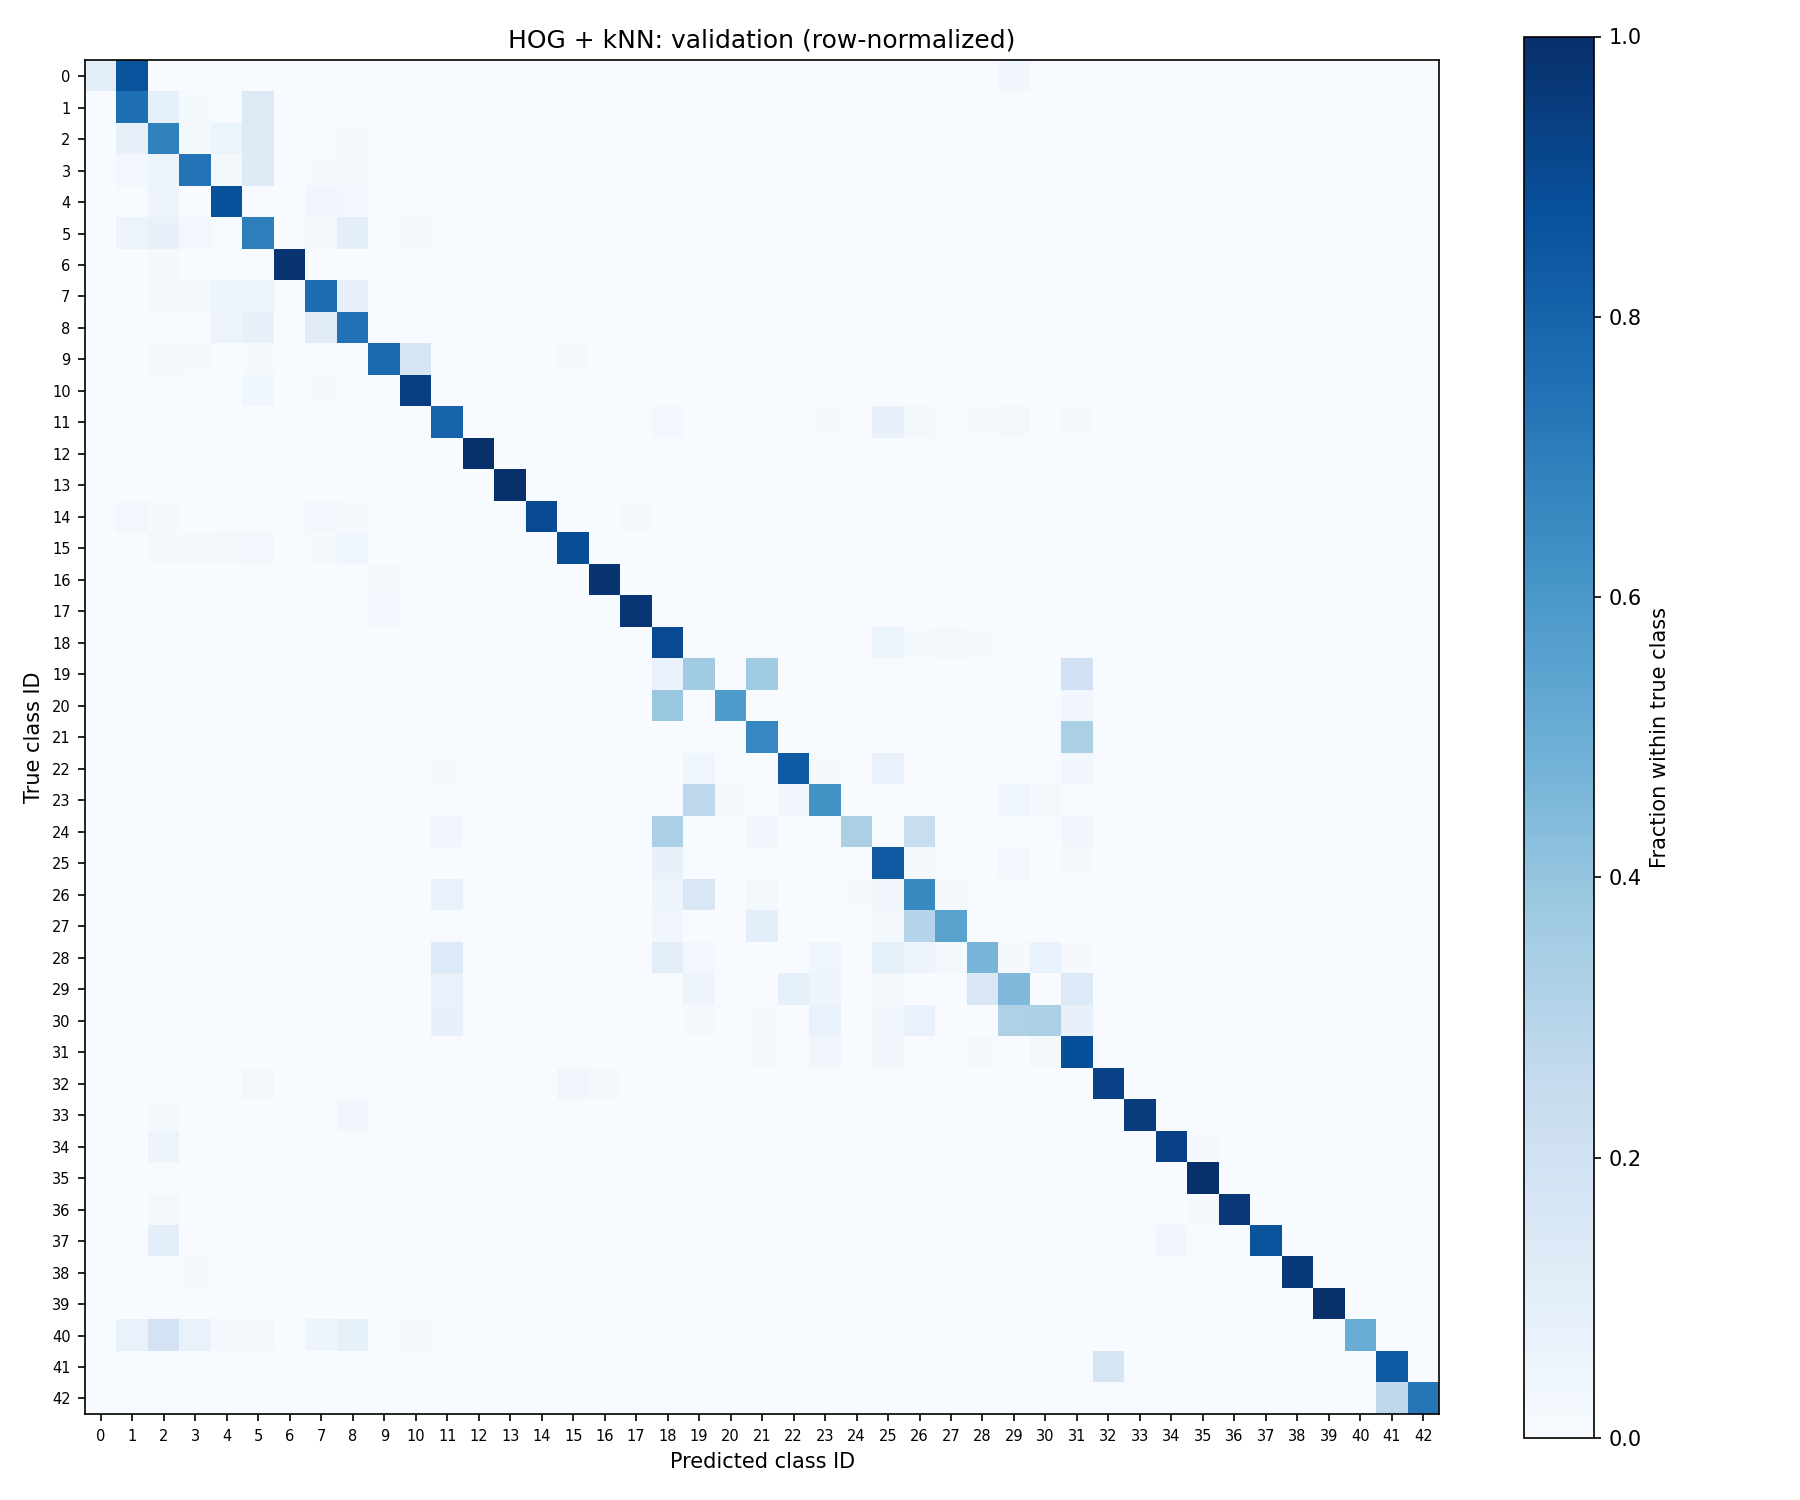

In [6]:
comparison = plot_results(PROJECT)
show_table(comparison.round(4))
display(Image(filename=str(PROJECT / "results/comparison/validation_comparison.png")))
display(Image(filename=str(OUTPUT / "validation_confusion_matrix.png")))
# Ma trận HSV cũng được lưu: results/hsv/validation_confusion_matrix.png

## 7. Nạp mô hình và xem ảnh đúng/sai

Mô hình lưu cùng cell size, cấu hình HOG, chuẩn hóa, kích thước ảnh và tên lớp.
Không diễn giải phiếu kNN thành xác suất chính xác.
Minh họa chọn 3 ảnh đúng và 3 ảnh sai, ưu tiên các lớp khác nhau để tránh lặp cùng một track.

Nhãn thật: 0 Giới hạn tốc độ 20 km/h
Dự đoán: 1 Giới hạn tốc độ 30 km/h


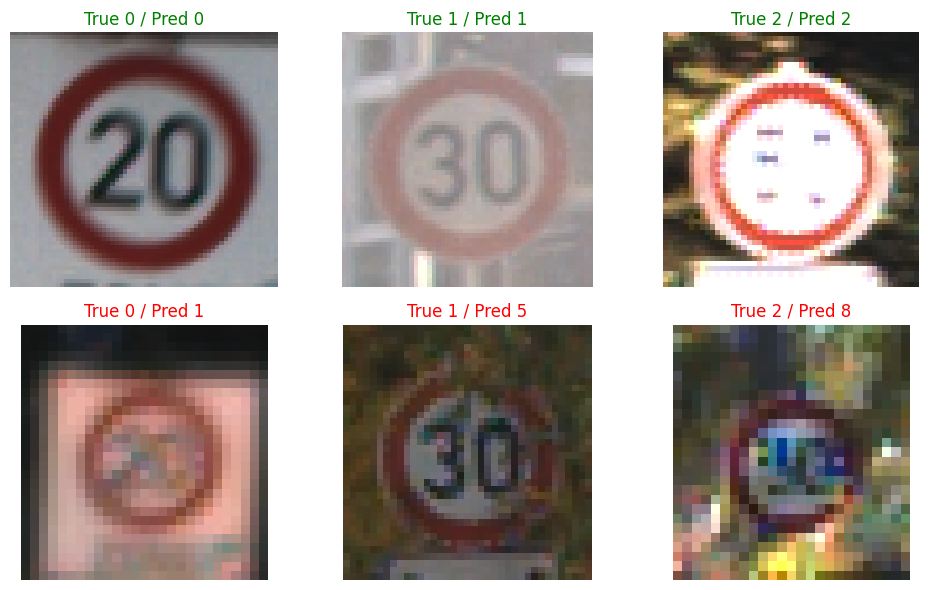

,,number_of_errors
true_class,predicted_class,
1,5,59
2,5,59
9,10,48
1,2,39
5,8,36
2,1,36
3,5,35
8,7,30
30,29,29


,class_id,precision,recall,f1-score,support
0,0,0.6000,0.1000,0.1714,30.0
1,1,0.7680,0.7578,0.7629,450.0
2,2,0.6769,0.6844,0.6807,450.0
3,3,0.8097,0.7407,0.7737,270.0
4,4,0.8149,0.8692,0.8412,390.0
5,5,0.5363,0.6972,0.6063,360.0
6,6,1.0000,0.9778,0.9888,90.0
7,7,0.7558,0.7633,0.7595,300.0
8,8,0.6667,0.7481,0.7051,270.0
9,9,0.9710,0.7800,0.8651,300.0


In [7]:
bundle = joblib.load(PROJECT / "models/hog_knn.joblib")
row = validation.iloc[0]
with threadpool_limits(limits=4):
    predicted = predict_hog(bundle, read_bgr(DATA / row.path))
print("Nhãn thật:", row.class_id, names.loc[row.class_id, "name_vi"])
print("Dự đoán:", predicted, names.loc[predicted, "name_vi"])

predictions = pd.read_csv(OUTPUT / "validation_predictions.csv")
examples = pd.concat([
    predictions[predictions.correct].drop_duplicates("true_class").head(3),
    predictions[~predictions.correct].drop_duplicates("true_class").head(3),
])
fig, axes = plt.subplots(2, 3, figsize=(10, 6))
for ax in axes.flat:
    ax.axis("off")
for ax, row in zip(axes.flat, examples.itertuples()):
    image = read_bgr(DATA / row.path)
    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    ax.set_title(f"True {row.true_class} / Pred {row.predicted_class}",
                 color="green" if row.correct else "red")
plt.tight_layout()
plt.savefig(OUTPUT / "validation_examples.png", dpi=150)
plt.show()

wrong = predictions[~predictions.correct]
pairs = wrong.groupby(["true_class", "predicted_class"]).size().sort_values(ascending=False)
show_table(pairs.head(10).rename("number_of_errors").to_frame())
show_table(pd.read_csv(OUTPUT / "validation_per_class.csv").round(4))

## 8. Bàn giao và giới hạn

- `features_hog.py`: hàm `hog_features` để người 4 kết hợp với HSV; `predict_hog` để demo dùng đúng cấu hình.
- `train_hog.py`: tìm tham số và lưu mô hình `models/hog_knn.joblib`.
- `plot_validation.py`: ma trận nhầm lẫn, bảng và biểu đồ so sánh từ CSV đã có.
- `results/hog/`: bảng đủ 12 cấu hình, dự đoán từng ảnh, chỉ số từng lớp, ma trận và hình minh họa.
- `results/comparison/`: bảng/biểu đồ so sánh validation HSV–HOG.
- `reports/hog_knn.md`: bản nháp phần báo cáo HOG và số liệu thực tế.

HOG giữ thông tin cạnh cục bộ nhưng bỏ màu; ảnh mờ/nhỏ, nghiêng, crop lệch và nền nhiều cạnh vẫn có thể gây lỗi.

**Cập nhật:** đánh giá test chung sau khi khóa ba phương pháp nằm ở `04_hsv_hog_knn.ipynb`. Các bảng trong notebook này là kết quả validation của giai đoạn chọn tham số.